In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

In [2]:
df = pd.read_csv("../data/processed/clean_terai_heatwave.csv")
df.head()

,Date,Year,Day_of_Year,Province,District,Regional_Hub,Latitude,Longitude,Max_Temp_C,Min_Temp_C,Mean_Temp_C,Humidity_Pct,Wind_Speed_ms,Precipitation_mm
0,2026-09-17,2026,260,Bagmati,Chitwan,Bharatpur,27.68,84.43,29.43,24.65,26.43,91.49,1.15,12.56
1,2026-09-17,2026,260,Gandaki,Nawalpur,Kawasoti,27.65,84.12,29.43,24.65,26.43,91.49,1.15,12.56
2,2026-09-17,2026,260,Koshi,Jhapa,Bhadrapur,26.54,88.08,30.02,24.77,26.82,90.43,0.92,9.43
3,2026-09-17,2026,260,Koshi,Morang,Biratnagar,26.45,87.27,30.55,25.11,27.26,89.39,0.73,8.12
4,2026-09-17,2026,260,Koshi,Sunsari,Inaruwa,26.60,87.15,31.03,25.35,27.71,88.39,0.78,7.52


### Univariate Analysis


In [3]:
df.columns

Index(['Date', 'Year', 'Day_of_Year', 'Province', 'District', 'Regional_Hub',
       'Latitude', 'Longitude', 'Max_Temp_C', 'Min_Temp_C', 'Mean_Temp_C',
       'Humidity_Pct', 'Wind_Speed_ms', 'Precipitation_mm'],
      dtype='str')

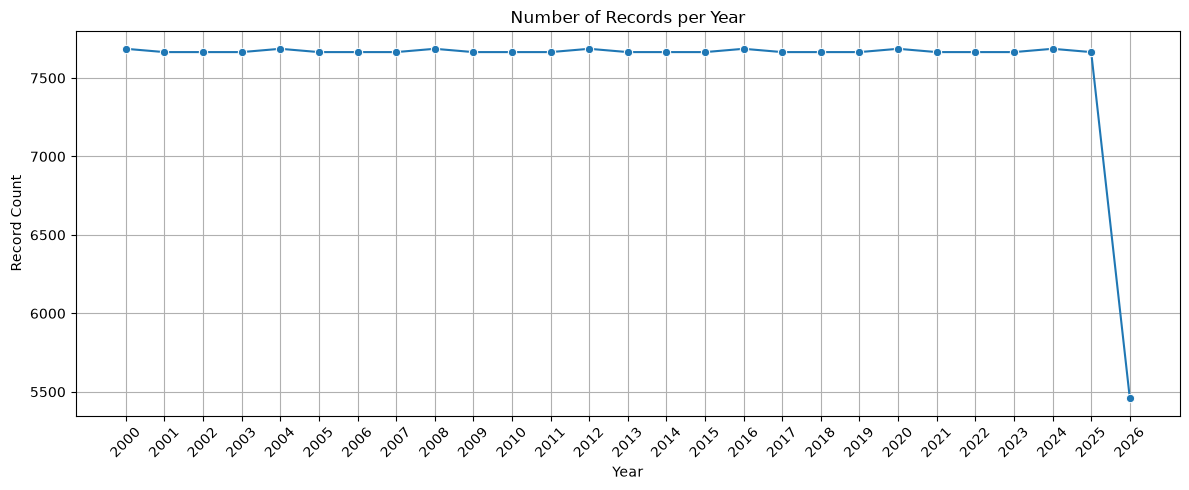

In [4]:

year_counts = df["Year"].value_counts().sort_index()
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=year_counts.index,
    y=year_counts.values,
    marker="o"
)

plt.title("Number of Records per Year")
plt.xlabel("Year")
plt.ylabel("Record Count")
plt.xticks(range(2000, 2027), rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

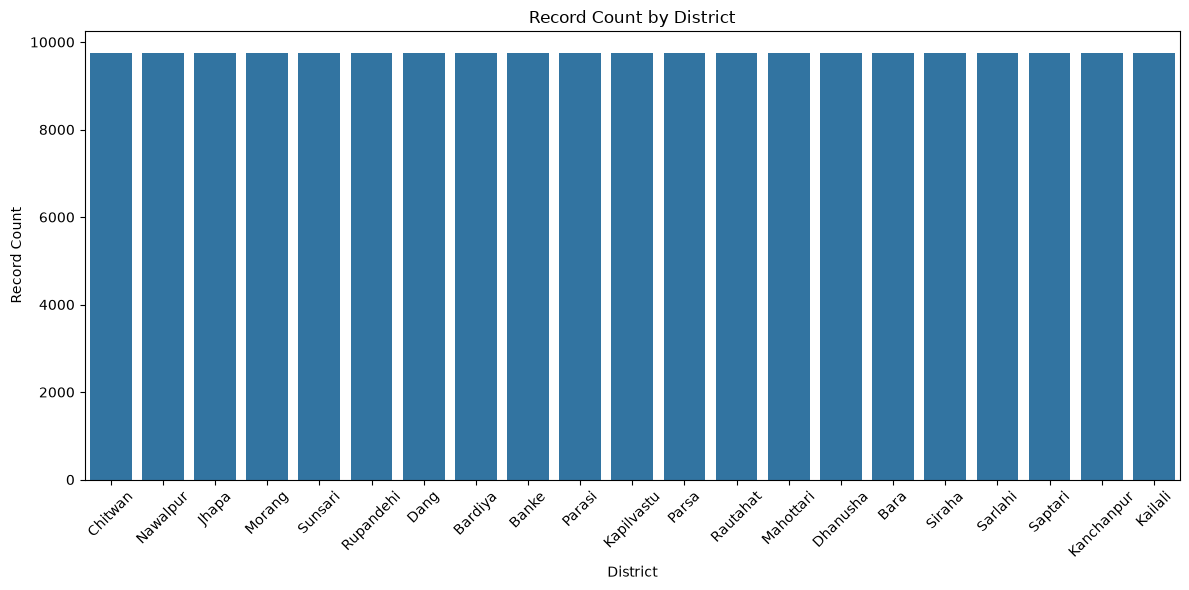

In [5]:
plt.figure(figsize=(12, 6))

sns.countplot(
    data=df,
    x="District",
    order=df["District"].value_counts().index
)

plt.title("Record Count by District")
plt.xlabel("District")
plt.ylabel("Record Count")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

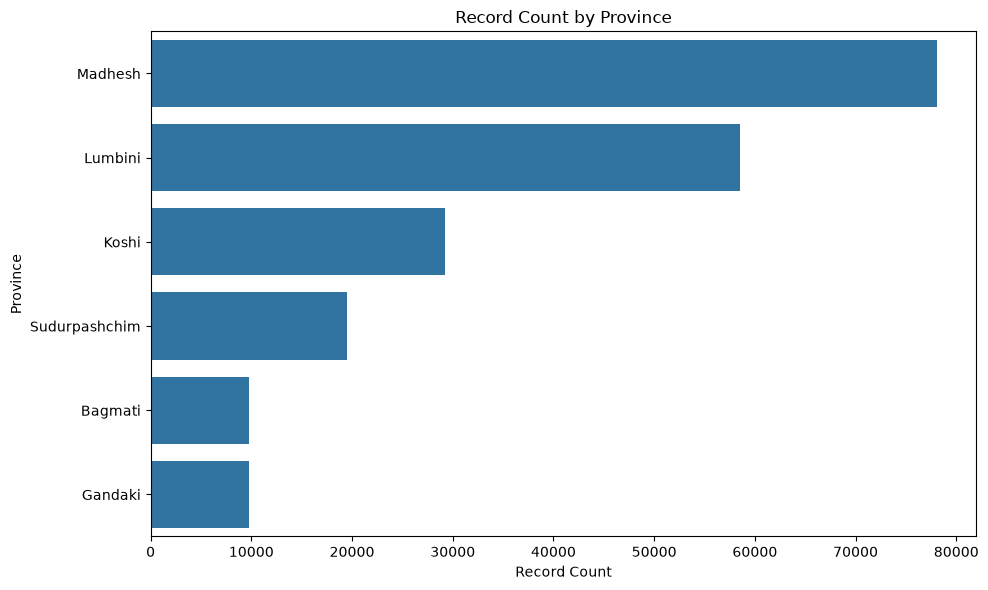

In [6]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    y="Province",
    order=df["Province"].value_counts().index
)

plt.title("Record Count by Province")
plt.xlabel("Record Count")
plt.ylabel("Province")

plt.tight_layout()
plt.show()

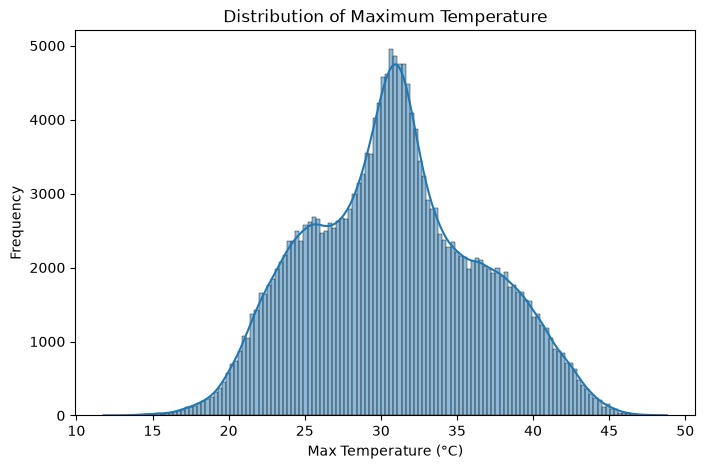

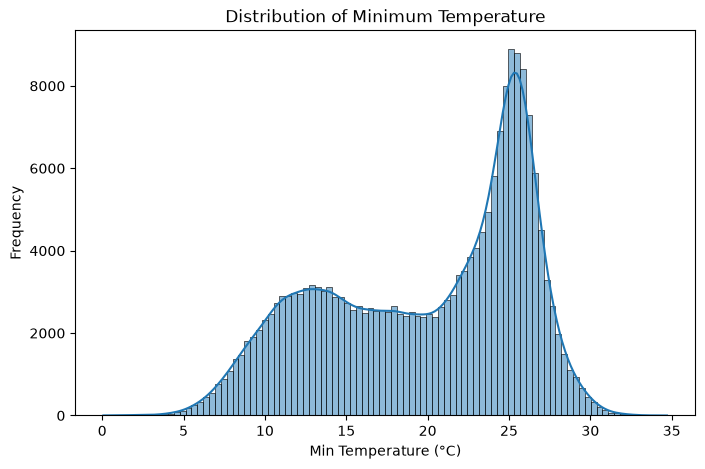

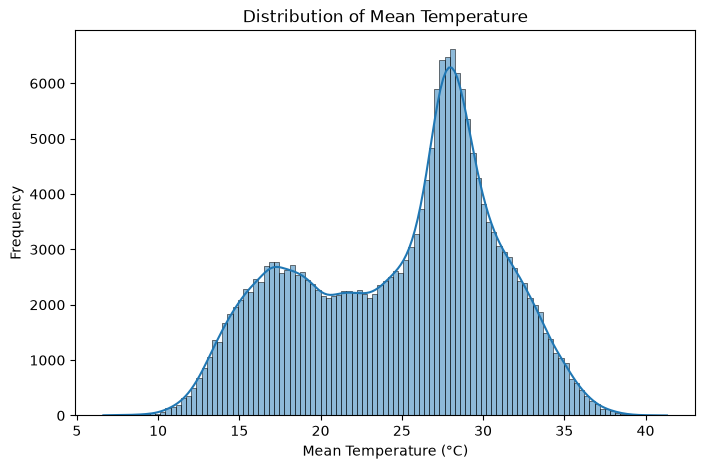

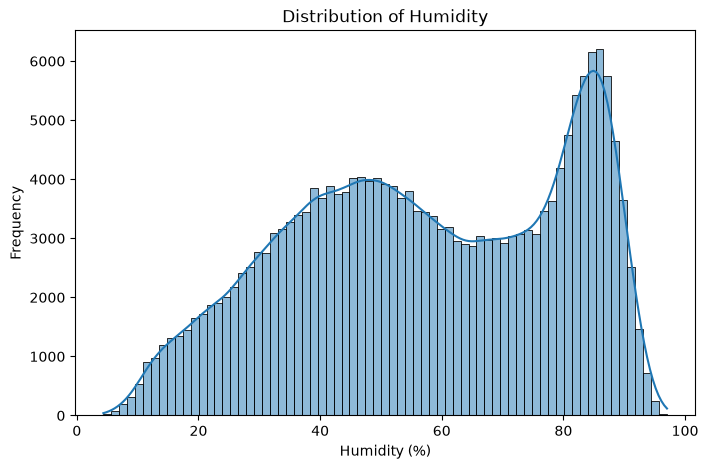

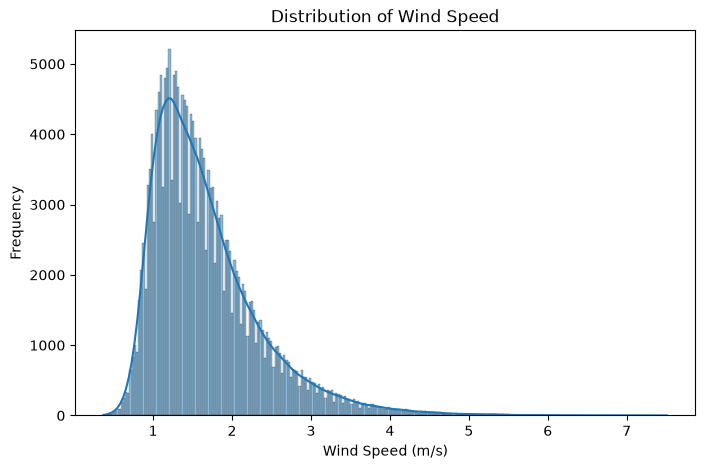

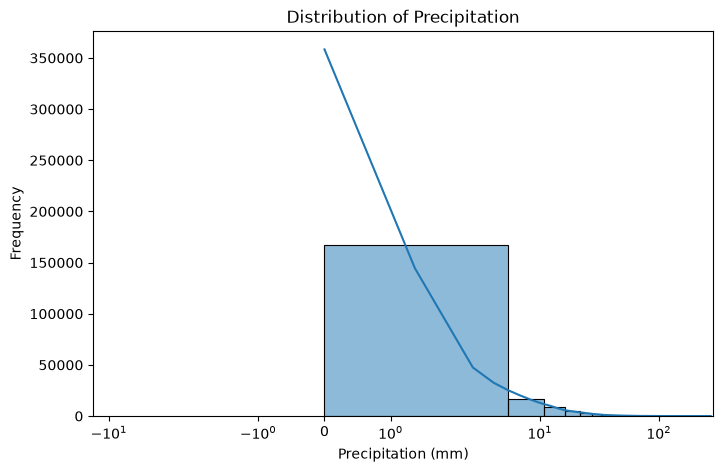

In [7]:
# Max Temperature
plt.figure(figsize=(8, 5))
sns.histplot(df["Max_Temp_C"], kde=True)
plt.title("Distribution of Maximum Temperature")
plt.xlabel("Max Temperature (°C)")
plt.ylabel("Frequency")
plt.show()


# Min Temperature
plt.figure(figsize=(8, 5))
sns.histplot(df["Min_Temp_C"], kde=True)
plt.title("Distribution of Minimum Temperature")
plt.xlabel("Min Temperature (°C)")
plt.ylabel("Frequency")
plt.show()


# Mean Temperature
plt.figure(figsize=(8, 5))
sns.histplot(df["Mean_Temp_C"], kde=True)
plt.title("Distribution of Mean Temperature")
plt.xlabel("Mean Temperature (°C)")
plt.ylabel("Frequency")
plt.show()


# Humidity
plt.figure(figsize=(8, 5))
sns.histplot(df["Humidity_Pct"], kde=True)
plt.title("Distribution of Humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("Frequency")
plt.show()


# Wind Speed
plt.figure(figsize=(8, 5))
sns.histplot(df["Wind_Speed_ms"], kde=True)
plt.title("Distribution of Wind Speed")
plt.xlabel("Wind Speed (m/s)")
plt.ylabel("Frequency")
plt.show()


# Precipitation
plt.figure(figsize=(8, 5))
sns.histplot(df["Precipitation_mm"], kde=True, bins=50)
plt.xscale("symlog")
plt.title("Distribution of Precipitation")
plt.xlabel("Precipitation (mm)")
plt.ylabel("Frequency")
plt.show()

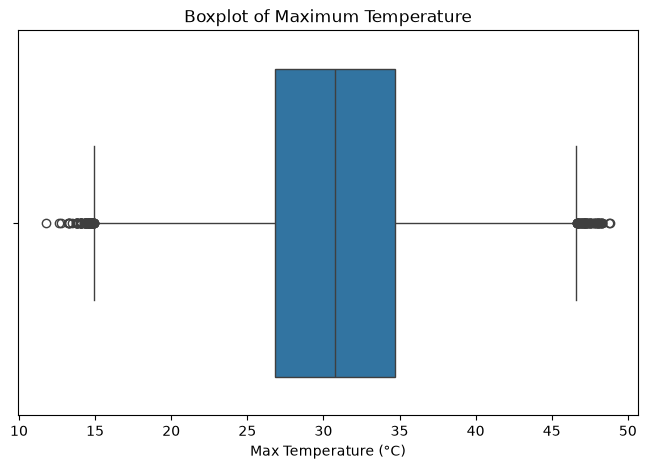

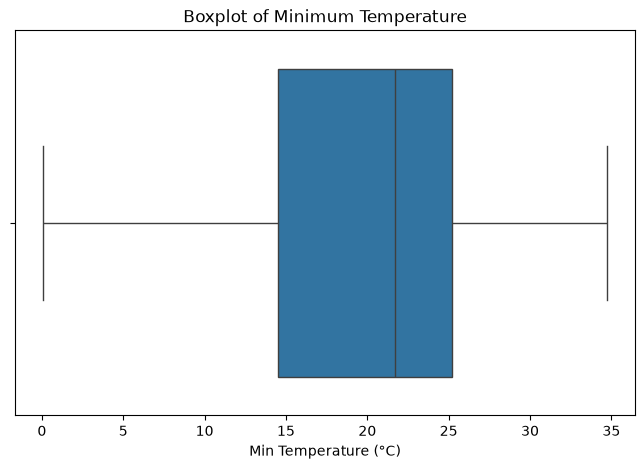

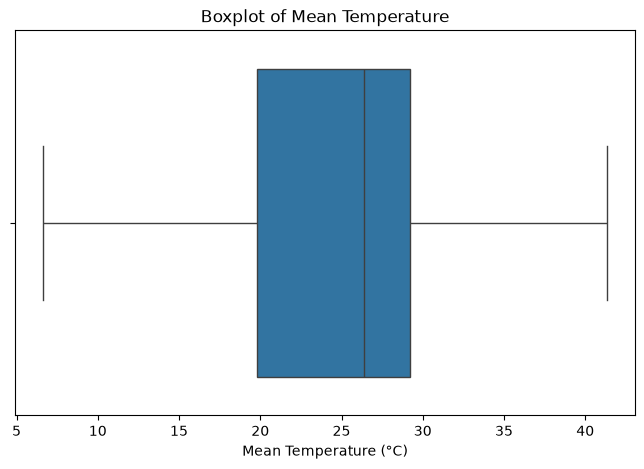

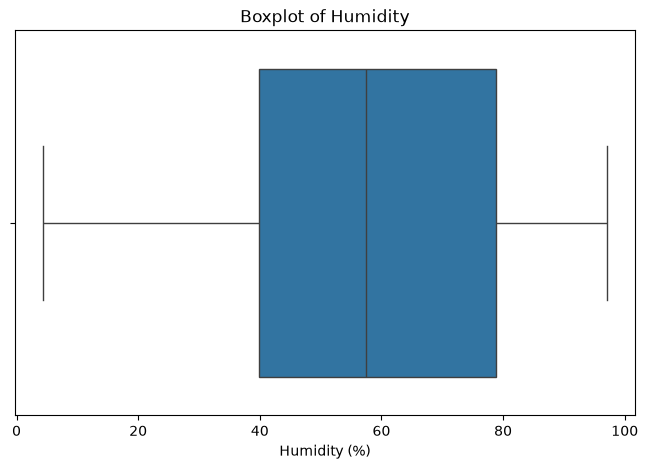

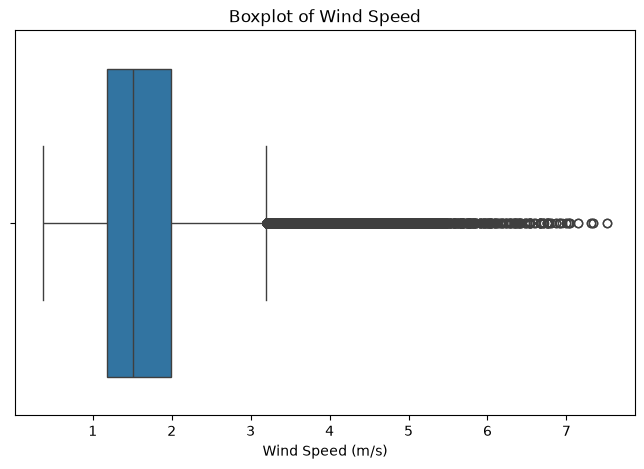

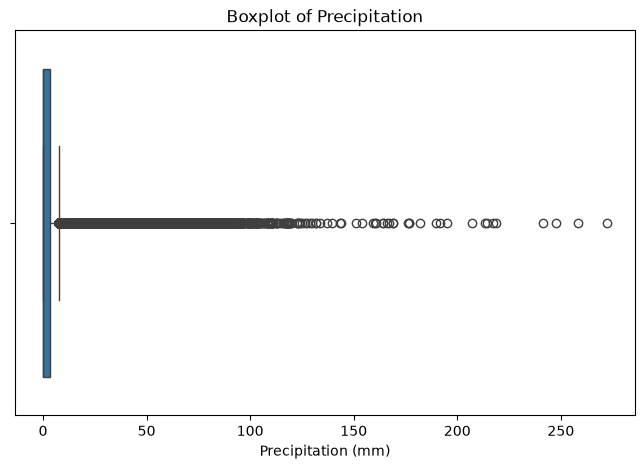

In [8]:
# Max Temperature
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Max_Temp_C"])
plt.title("Boxplot of Maximum Temperature")
plt.xlabel("Max Temperature (°C)")
plt.show()

# Min Temperature
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Min_Temp_C"])
plt.title("Boxplot of Minimum Temperature")
plt.xlabel("Min Temperature (°C)")
plt.show()

# Mean Temperature
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Mean_Temp_C"])
plt.title("Boxplot of Mean Temperature")
plt.xlabel("Mean Temperature (°C)")
plt.show()

# Humidity
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Humidity_Pct"])
plt.title("Boxplot of Humidity")
plt.xlabel("Humidity (%)")
plt.show()

# Wind Speed
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Wind_Speed_ms"])
plt.title("Boxplot of Wind Speed")
plt.xlabel("Wind Speed (m/s)")
plt.show()

# Precipitation
plt.figure(figsize=(8, 5))
sns.boxplot(x=df["Precipitation_mm"])
plt.title("Boxplot of Precipitation")
plt.xlabel("Precipitation (mm)")
plt.show()

### Bivariate Analysis

#### Climate vs. Geography

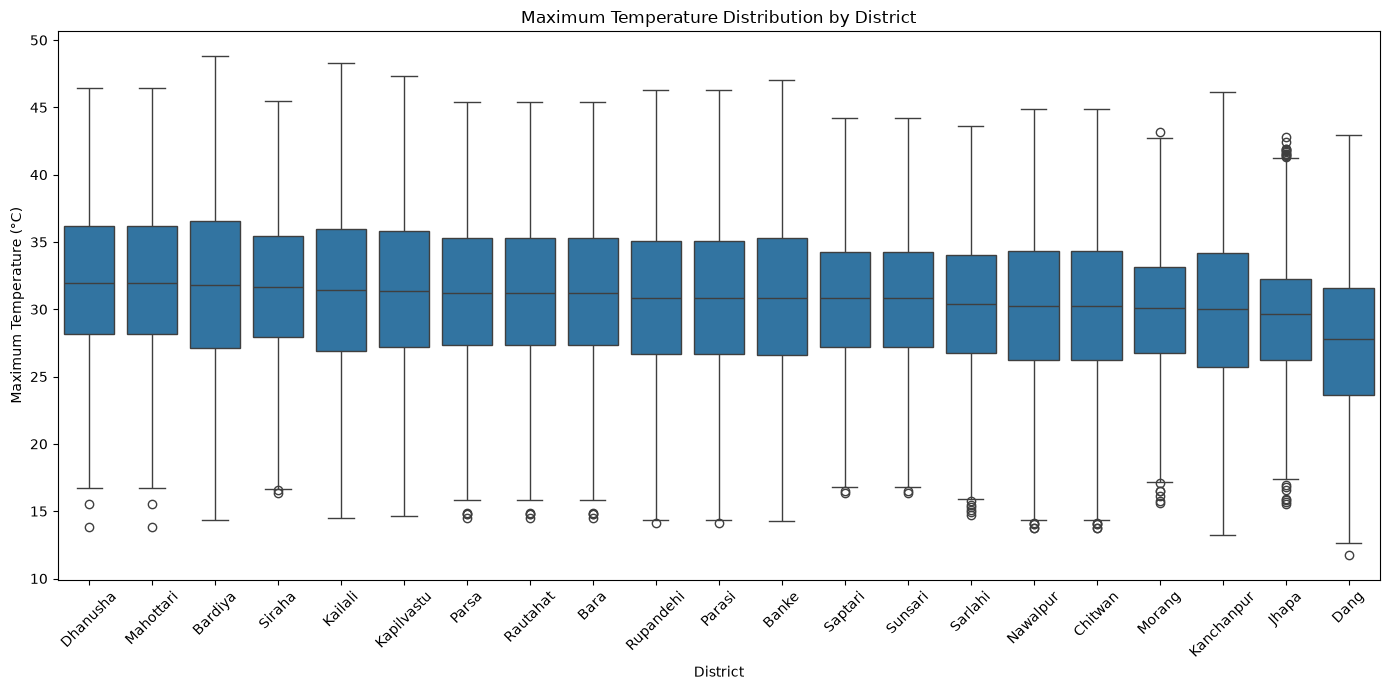

In [9]:
district_order = (
    df.groupby("District")["Max_Temp_C"]
      .median()
      .sort_values(ascending=False)
      .index
)

plt.figure(figsize=(14, 7))

sns.boxplot(
    data=df,
    x="District",
    y="Max_Temp_C",
    order=district_order
)

plt.title("Maximum Temperature Distribution by District")
plt.xlabel("District")
plt.ylabel("Maximum Temperature (°C)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

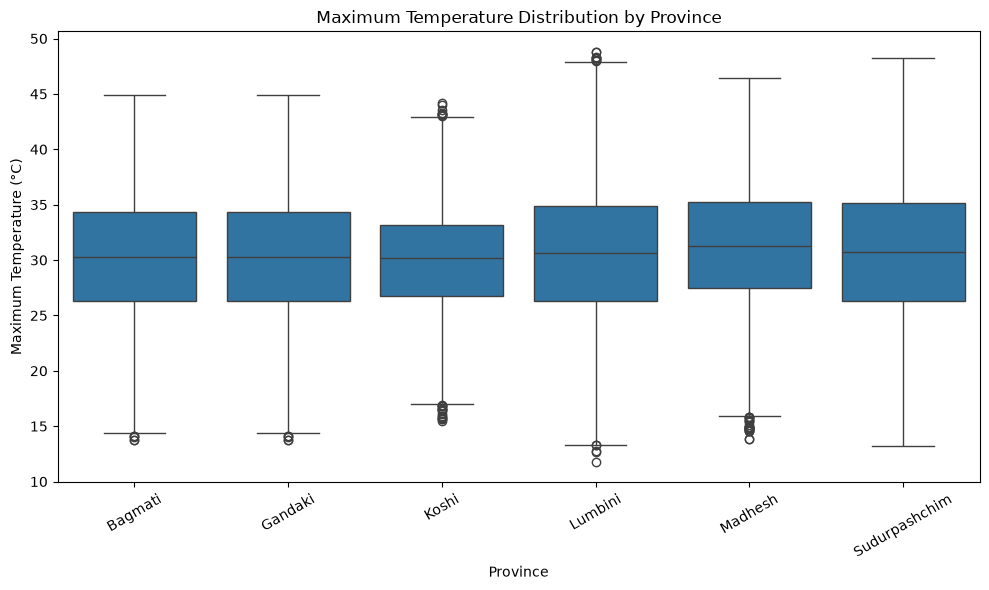

In [12]:
plt.figure(figsize=(10, 6))

sns.boxplot(
    data=df,
    x="Province",
    y="Max_Temp_C"
)

plt.title("Maximum Temperature Distribution by Province")
plt.xlabel("Province")
plt.ylabel("Maximum Temperature (°C)")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

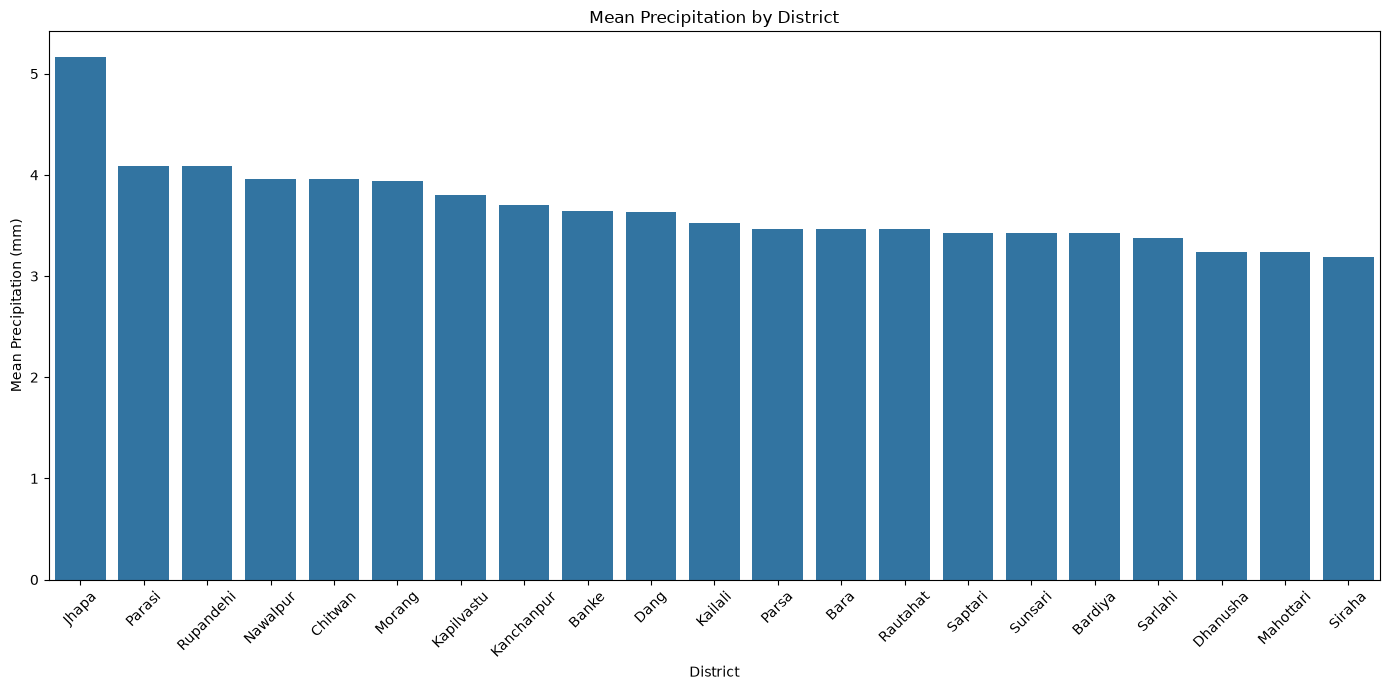

In [13]:
rainfall = (
    df.groupby("District")["Precipitation_mm"]
      .mean()
      .sort_values(ascending=False)
      .reset_index()
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=rainfall,
    x="District",
    y="Precipitation_mm"
)

plt.title("Mean Precipitation by District")
plt.xlabel("District")
plt.ylabel("Mean Precipitation (mm)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Climate vs. Time

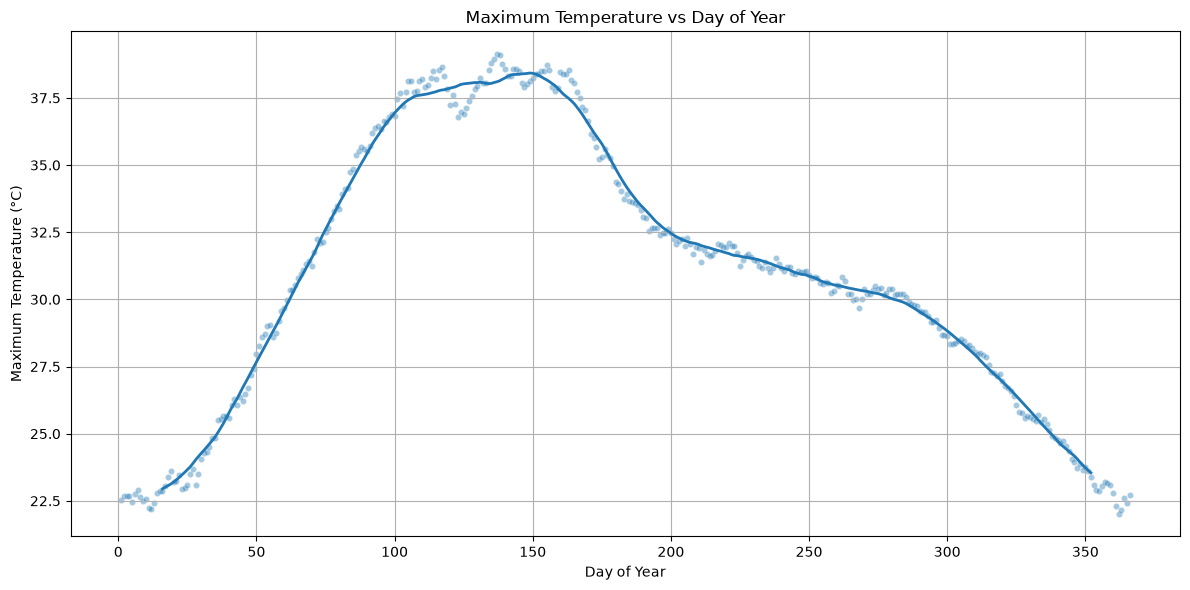

In [14]:
# Calculate 30-day moving average
doy_temp = (
    df.groupby("Day_of_Year")["Max_Temp_C"]
      .mean()
      .sort_index()
)

moving_avg = doy_temp.rolling(window=30, center=True).mean()

plt.figure(figsize=(12, 6))

sns.scatterplot(
    x=doy_temp.index,
    y=doy_temp.values,
    alpha=0.4,
    s=20
)

plt.plot(
    doy_temp.index,
    moving_avg,
    linewidth=2
)

plt.title("Maximum Temperature vs Day of Year")
plt.xlabel("Day of Year")
plt.ylabel("Maximum Temperature (°C)")
plt.grid(True)

plt.tight_layout()
plt.show()

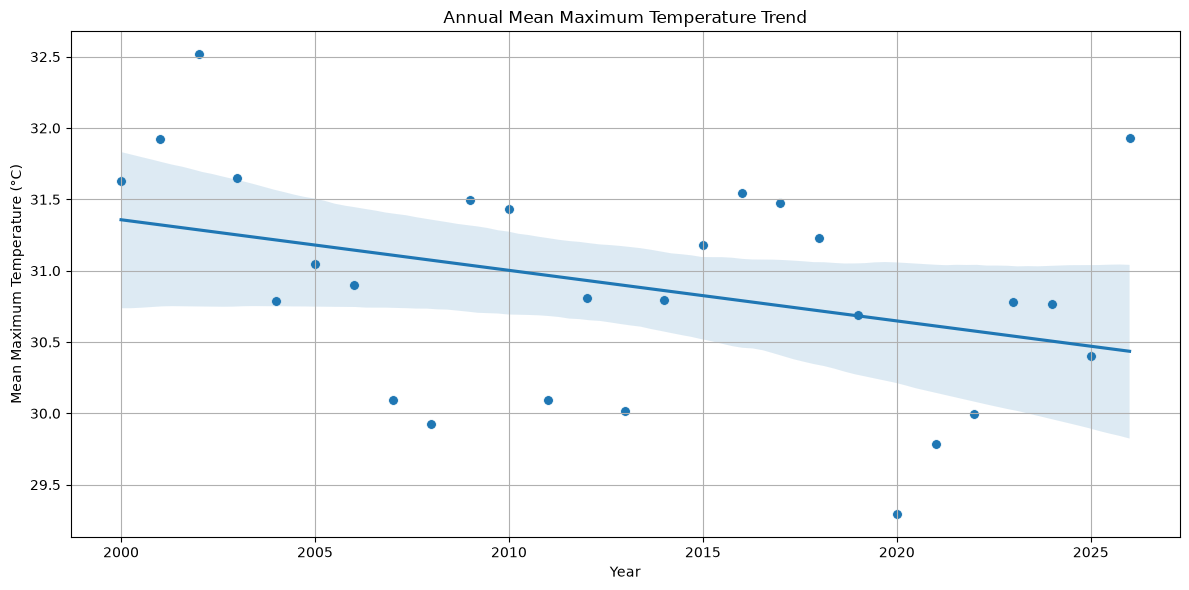

In [15]:
annual_temp = (
    df.groupby("Year")["Max_Temp_C"]
      .mean()
      .reset_index()
)

plt.figure(figsize=(12, 6))

sns.scatterplot(
    data=annual_temp,
    x="Year",
    y="Max_Temp_C",
    s=50
)

sns.regplot(
    data=annual_temp,
    x="Year",
    y="Max_Temp_C",
    scatter=False
)

plt.title("Annual Mean Maximum Temperature Trend")
plt.xlabel("Year")
plt.ylabel("Mean Maximum Temperature (°C)")
plt.grid(True)

plt.tight_layout()
plt.show()

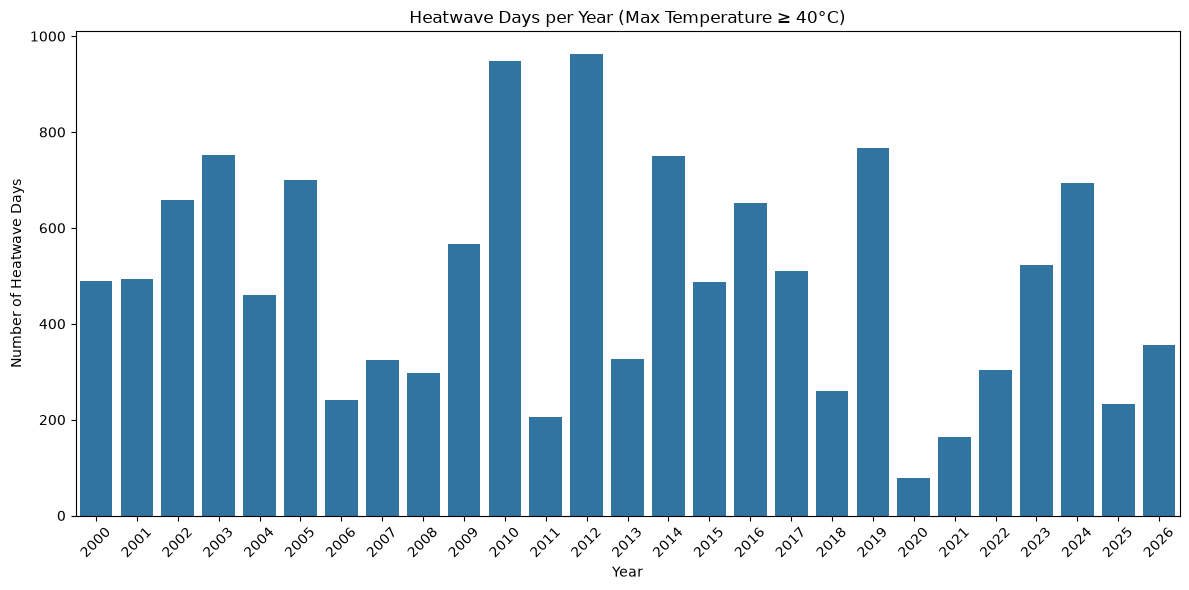

In [16]:
heatwave_days = (
    df[df["Max_Temp_C"] >= 40]
    .groupby("Year")
    .size()
    .reset_index(name="Heatwave_Days")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=heatwave_days,
    x="Year",
    y="Heatwave_Days"
)

plt.title("Heatwave Days per Year (Max Temperature ≥ 40°C)")
plt.xlabel("Year")
plt.ylabel("Number of Heatwave Days")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

#### Climate vs. Climate.

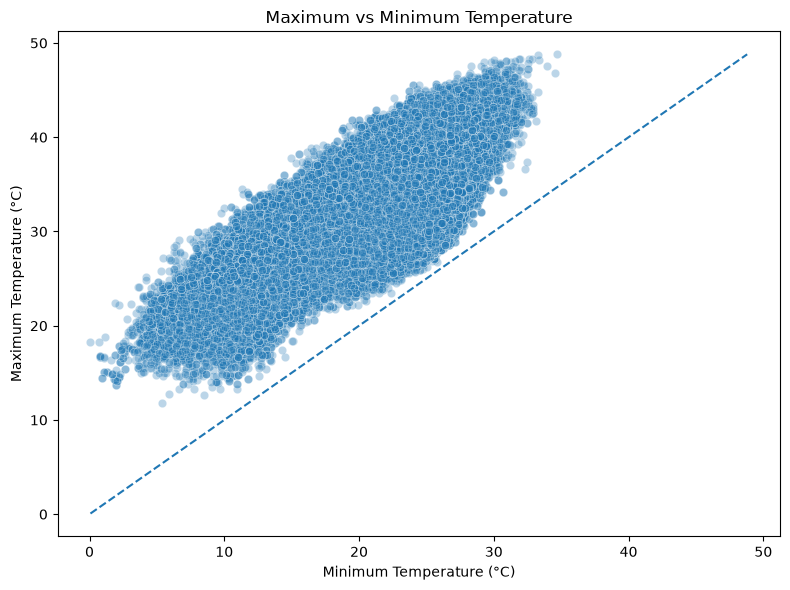

In [17]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Min_Temp_C",
    y="Max_Temp_C",
    alpha=0.3
)

# Identity line: Max Temp = Min Temp
min_temp = df["Min_Temp_C"].min()
max_temp = df["Max_Temp_C"].max()

plt.plot(
    [min_temp, max_temp],
    [min_temp, max_temp],
    linestyle="--"
)

plt.title("Maximum vs Minimum Temperature")
plt.xlabel("Minimum Temperature (°C)")
plt.ylabel("Maximum Temperature (°C)")

plt.tight_layout()
plt.show()

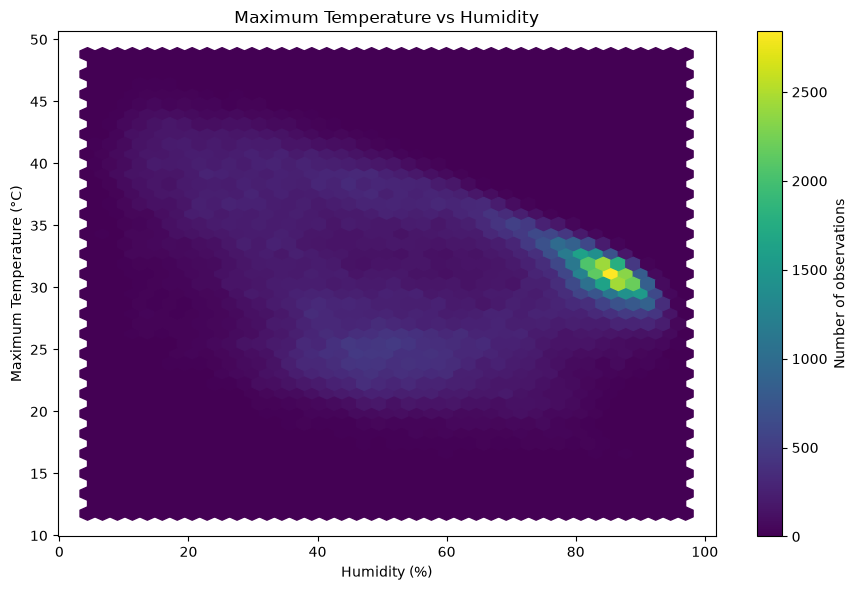

In [18]:
plt.figure(figsize=(9, 6))

plt.hexbin(
    df["Humidity_Pct"],
    df["Max_Temp_C"],
    gridsize=40,
    cmap="viridis"
)

plt.colorbar(label="Number of observations")

plt.title("Maximum Temperature vs Humidity")
plt.xlabel("Humidity (%)")
plt.ylabel("Maximum Temperature (°C)")

plt.tight_layout()
plt.show()

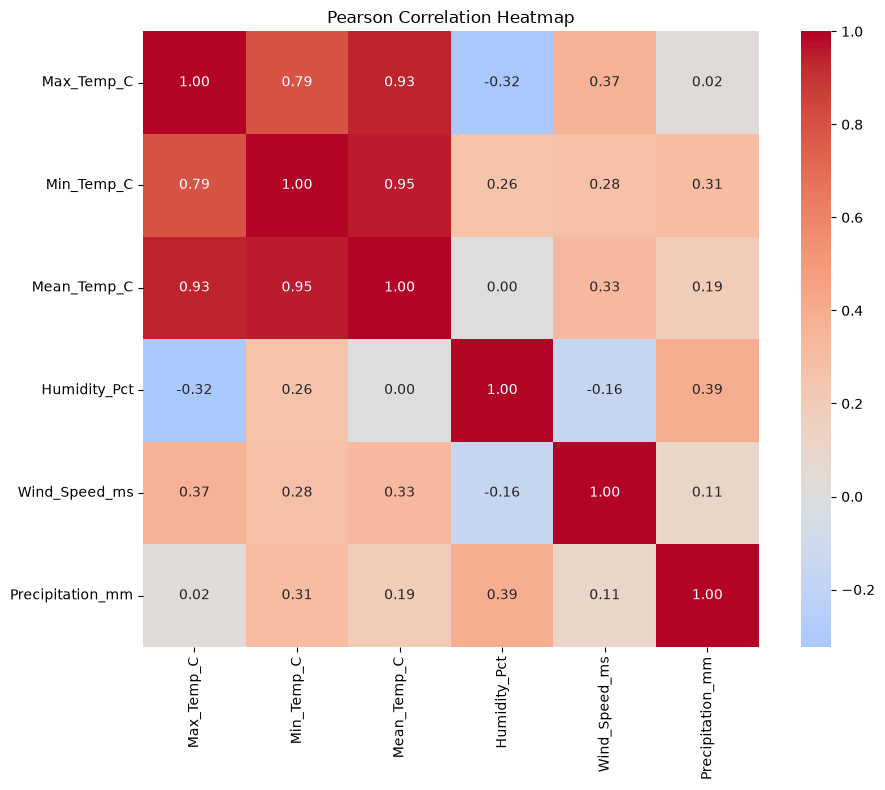

In [19]:
numeric_cols = [
    "Max_Temp_C",
    "Min_Temp_C",
    "Mean_Temp_C",
    "Humidity_Pct",
    "Wind_Speed_ms",
    "Precipitation_mm"
]

corr = df[numeric_cols].corr(method="pearson")

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True
)

plt.title("Pearson Correlation Heatmap")

plt.tight_layout()
plt.show()

In [20]:
import numpy as np

T = df["Max_Temp_C"] * 9/5 + 32
RH = df["Humidity_Pct"]

heat_index_f = (
    -42.379
    + 2.04901523 * T
    + 10.14333127 * RH
    - 0.22475541 * T * RH
    - 0.00683783 * T**2
    - 0.05481717 * RH**2
    + 0.00122874 * T**2 * RH
    + 0.00085282 * T * RH**2
    - 0.00000199 * T**2 * RH**2
)

df["Heat_Index_C"] = (heat_index_f - 32) * 5/9

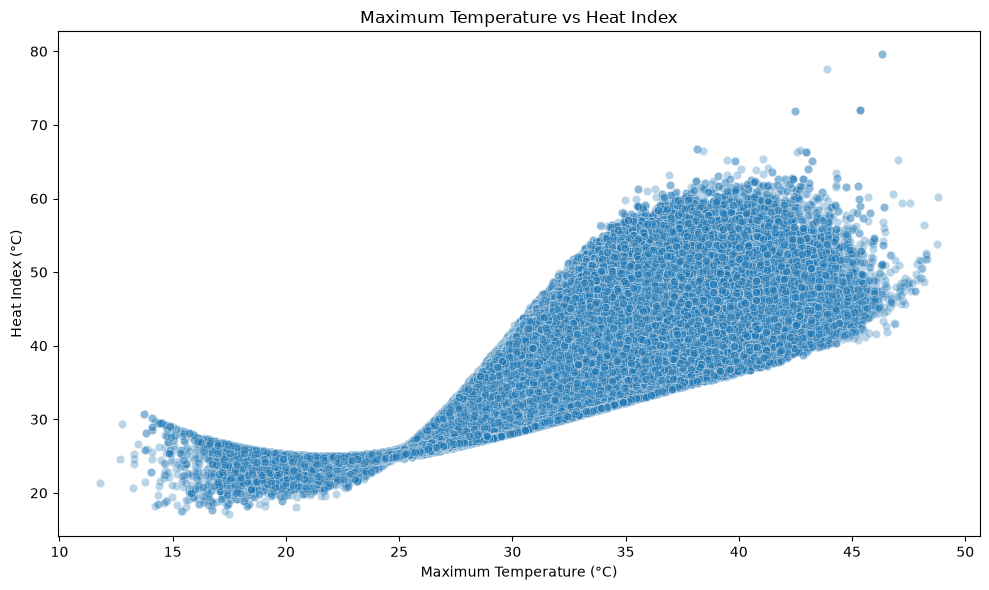

In [21]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="Max_Temp_C",
    y="Heat_Index_C",
    alpha=0.3
)

plt.title("Maximum Temperature vs Heat Index")
plt.xlabel("Maximum Temperature (°C)")
plt.ylabel("Heat Index (°C)")

plt.tight_layout()
plt.show()

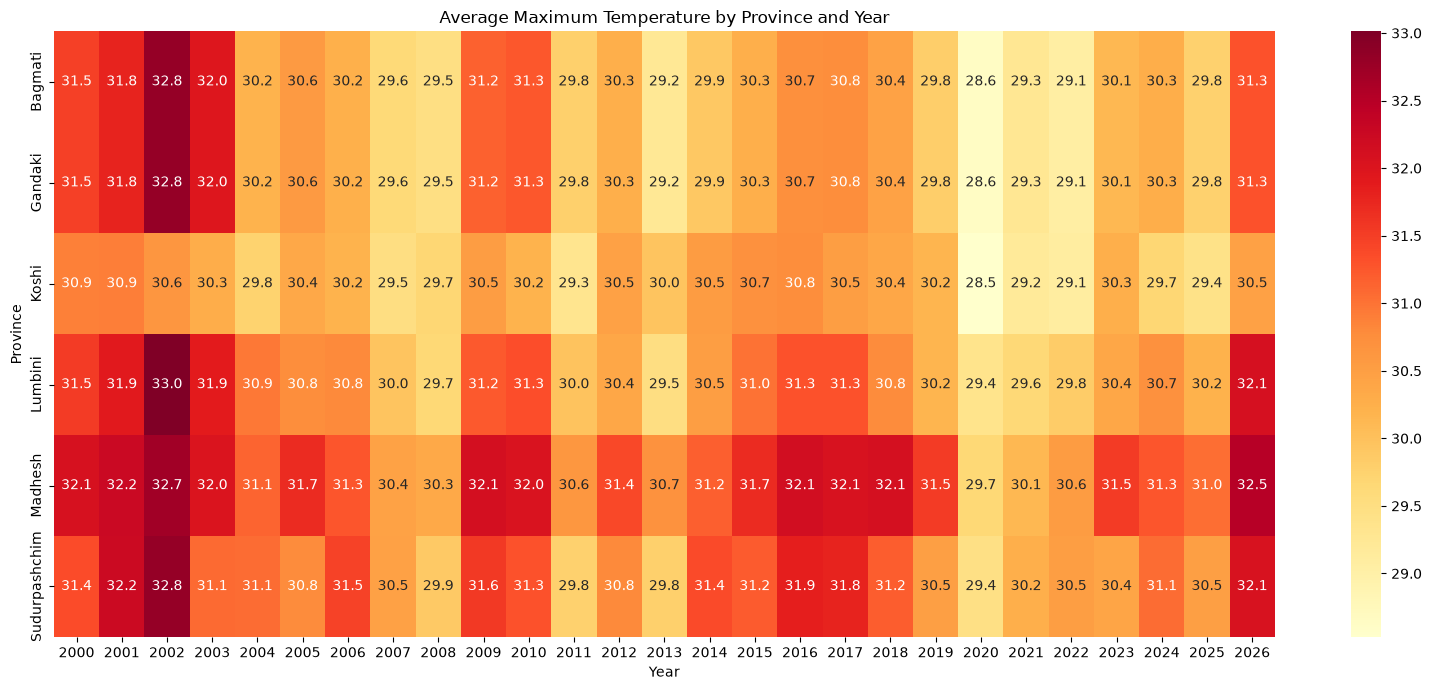

In [22]:
province_year = (
    df.groupby(["Province", "Year"])["Max_Temp_C"]
      .mean()
      .unstack()
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    province_year,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd"
)

plt.title("Average Maximum Temperature by Province and Year")
plt.xlabel("Year")
plt.ylabel("Province")

plt.tight_layout()
plt.show()